# Project week 7

For the project this week, you are given a video of a ball rolling over a surface. Your job is now to detect the ball, track the position, velocity and acceleration using a Kalman filter, and finally draw the currently tracked position and predicted position of the ball in the images, while also printing the whole predicted state in either the image or the terminal.

The video "rolling_ball_result.mp4" shows what the end result could look like.

You have to make the Kalman filter yourselves, i.e. initialize the matrices and make a update and predict function. You are of course allowed to use numpy.

You can use the code below and fill in the missing parts.



In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.cm as cm

In [ ]:
def update(x, P, Z, H, R):
    y=Z-np.dot(H,x)
    S=np.dot(H , np.dot(P, H.T))+R
    K=np.dot(P, np.dot(H.T, np.linalg.pinv(S)))
    x=x+np.dot(K,y)
    P=np.dot(np.eye(np.size(x))-np.dot(K,H),P)
    return [x, P]
    
def predict(x, P, F, u):
    x=np.dot(F,x)+u
    P=np.dot(F, np.dot(P, F.T))
    return [x, P]
    
    
### Initialize Kalman filter ###
# The initial state (6x1).
x = np.array([[0],
              [0],
              [0],
              [0],
              [0],
              [0]])


# The initial uncertainty (6x6).
P = np.array(np.eye(np.size(x))*1000)

# The external motion (6x1).
u = np.array([[0],
              [0],
              [0],
              [0],
              [0],
              [0]])

# The transition matrix (6x6). 
F = np.array([[1, 1, 0.5, 0, 0, 0],
              [0, 1, 0, 0, 0, 0],
              [0, 0, 1, 0, 0, 0],
              [0, 0, 0, 1, 1, 0.5],
              [0, 0, 0, 0, 1, 0],
              [0, 0, 0, 0, 0, 1]])

# The observation matrix (2x6).
H = np.array([[1, 0, 0, 0, 0, 0],
              [0, 0, 0, 1, 0, 0]])

# The measurement uncertainty.
R = np.array(np.eye(2)*2)

I=np.array(np.eye(np.size(x)))


# Load the video
cap = cv2.VideoCapture('rolling_ball.mp4')
if not cap.isOpened():
    print("Cannot open video")
    exit()


cv2.namedWindow('Frame', cv2.WINDOW_NORMAL)
cv2.resizeWindow('Frame', 1600, 800)

# Minimum and maximum movement between two consecutive frames (pixels).
threshold = 15
max_movement = 100
previous_circles = []
initialized = False

### TO SAVE A VIDEO OF THE OUTPUT
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

writer = cv2.VideoWriter(
    'rolling_ball_my_result.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps,
    (width, height)
)
###

# Looping through all the frames
while True:
    ret, frame = cap.read()
    if not ret:
        break
        
    ### Detect the ball ###
    b, g, r = cv2.split(frame)
    img = cv2.merge([r, g, b])


    # Grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Smoothing to make circle detection easier
    gray_blur = cv2.GaussianBlur(gray, (9, 9), 2)

    # Hough Circle Transform
    circles = cv2.HoughCircles(
        gray_blur,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=100,
        param1=20,
        param2=25,
        minRadius=55,
        maxRadius=85
    )

    # Copy to draw on
    output = img.copy()
    
    center = None
    radius = None
    current_circles = []

    if circles is not None:
        current_circles = np.round(circles[0]).astype(int)

        for cx, cy, cr in current_circles:
            min_distance = float("inf")

            # Find the closest centre in the previous frame.
            for px, py, pr in previous_circles:
                dx = cx - px
                dy = cy - py
                distance = np.sqrt(dx**2 + dy**2)
                min_distance = min(min_distance, distance)

            # Draw only the centres that have moved, as in Week 2.
            if threshold < min_distance <= max_movement:
                center = (cx, cy)
                radius = cr
                cv2.circle(output, center, radius, (255, 0, 0), 3)
                cv2.circle(output, center, 3, (0, 255, 0), -1)

    # The current frame becomes the previous one, including the static circles.
    previous_circles = current_circles.copy()
    
    ### If the ball is found, update the Kalman filter ###
    if center is not None:
        Z = np.array([[center[0]],
                      [center[1]]], dtype=float)

        if not initialized:
            x[0, 0] = center[0]
            x[3, 0] = center[1]
            initialized = True
        else:
            x, P = update(x, P, Z, H, R)

    ### Predict the next state
    if initialized:
        tracked_center = (round(x[0, 0]), round(x[3, 0]))

        x, P = predict(x, P, F, u)

        predicted_center = (round(x[0, 0]), round(x[3, 0]))
    
    ### Draw the current tracked state and the predicted state on the image frame ###
    if initialized:
        # Estimated current position: green.
        cv2.circle(output, tracked_center, 75, (0, 255, 0), 3)

        # Predicted position for the next frame: yellow.
        cv2.circle(output, predicted_center, 75, (0, 255, 255), 3)

        # Predicted state: [pos_x, vel_x, acc_x, pos_y, vel_y, acc_y].
        print("Predicted state:", x.ravel())
    
    
    writer.write(cv2.cvtColor(output, cv2.COLOR_RGB2BGR))
    
    # Show the frame
    cv2.imshow('Frame', output)
    cv2.waitKey(50)
    
cap.release()
writer.release()
cv2.destroyAllWindows()

Predicted state: [1806.    0.    0.  688.    0.    0.]
Predicted state: [ 1.74694139e+03 -1.68738899e+01 -8.43694494e+00  6.94216696e+02
  1.77619893e+00  8.88099467e-01]
Predicted state: [1676.28149931  -36.64575872  -18.32287936  707.93045423    6.36081686
    3.18040843]
Predicted state: [1622.1178538   -39.14969413  -19.57484706  710.65268657    4.7940566
    2.3970283 ]
Predicted state: [1561.07786069  -42.0522199   -21.02610995  715.99337751    4.63772202
    2.31886101]
Predicted state: [1517.24314865  -40.30704879  -20.15352439  721.79582369    4.63878018
    2.31939009]
Predicted state: [1468.69613429  -39.99230235  -19.99615118  727.73033467    4.66209075
    2.33104537]
Predicted state: [1417.16583344  -40.22321057  -20.11160529  735.99660834    5.02776275
    2.51388138]
Predicted state: [1373.30143138  -39.36818138  -19.68409069  742.28300696    5.02798871
    2.51399435]
Predicted state: [1326.17877825  -39.1177368   -19.5588684   750.21945251    5.22611304
    2.61305652

## Hints

The first part is to detect the ball. For this part you can look back to the exercises from week 2. More specifically the end of exercise 1. You may have to adjust some parameters in order to only detect the ball.

The next part is to make the Kalman filter. If you did the exercises from monday this week, you already have a suitable update and predict function. You will have to initialize all the different matrices, which we also did in the exercises, however this time we would like the state to include position, velocity and acceleration in both the x- and y-direction (6 states).

Start by defining your state **x** and uncertainty **P**. Then define a transition matrix **F** based on your state. When defining the state transition last time we used the equation for linear motion:

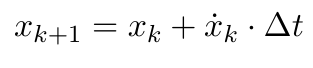

We used dt = 1 (delta t), for simplicity. You can do the same here. However, this time we also have the acceleration and therefore we use:

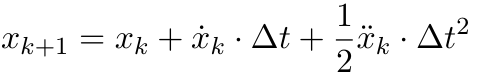

Finally, for a part of the video, the ball is behind something and can't be seen. Obviously we cant update our state here, because there is no measurement. So when there is no measurements available, you should only use the predict function and not the update function, to estimate the state.


# Challenge

If you can't get enough of tracking and Kalman filters, try extending your program, such that it can keep track of multiple balls at the same time. Use the video "rolling_ball_challenge.mp4" to test it. You can take advantage of the balls having different colours.

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# HSV ranges per ball colour
COLOUR_RANGES = {
    'red': [((0, 150, 50), (8, 255, 180)), ((170, 150, 50), (180, 255, 180))],
    'yellow': [((20, 100, 100), (35, 255, 255))],
    'blue': [((85, 80, 20), (110, 255, 200))],
}


def detect_ball(frame, colour):
    """Return (x, y, radius) of the ball with this colour, or None if it is not visible."""
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = np.zeros(hsv.shape[:2], np.uint8)
    for lower, upper in COLOUR_RANGES[colour]:
        mask |= cv2.inRange(hsv, lower, upper)

    # Remove small specks, then blur so the disc has smooth edges for the gradient-based Hough
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    mask = cv2.GaussianBlur(mask, (9, 9), 2)

    circles = cv2.HoughCircles(mask, cv2.HOUGH_GRADIENT, dp=2, minDist=200,
                               param1=100, param2=30, minRadius=50, maxRadius=90)
    if circles is None:
        return None
    return circles[0][0]

In [4]:
def update(x, P, Z, H, R):
    y = Z - H @ x                      # innovation, 2x1
    S = H @ P @ H.T + R                # innovation covariance, 2x2
    K = P @ H.T @ np.linalg.pinv(S)    # Kalman gain, 6x2
    x = x + K @ y
    P = (np.eye(len(x)) - K @ H) @ P
    return x, P


def predict(x, P, F, u, Q):
    x = F @ x + u
    P = F @ P @ F.T + Q
    return x, P


# Initialize Kalman filter
# State order: [x, vx, ax, y, vy, ay]
# The initial state (6x1). Replaced by the first detection when a track starts
x = np.zeros((6, 1))

# The initial uncertainty (6x6). We know nothing about velocity and acceleration yet
P = np.eye(6) * 1000

# The external motion (6x1)
u = np.zeros((6, 1))

# The transition matrix (6x6). The same constant-acceleration block for x and for y, dt = 1 frame
dt = 1
block = np.array([[1, dt, 0.5 * dt**2],
                  [0, 1,  dt],
                  [0, 0,  1]])
F = np.block([[block, np.zeros((3, 3))],
              [np.zeros((3, 3)), block]])

# The observation matrix (2x6). We only measure the positions
H = np.array([[1, 0, 0, 0, 0, 0],
              [0, 0, 0, 1, 0, 0]])

# The measurement uncertainty (2x2), roughly 5 px standard deviation
R = np.eye(2) * 25

# The process noise (6x6)
Q = np.eye(6) * 1

In [5]:
DRAW = {'current': (0, 200, 0), 'prediction': (255, 0, 0)}   # BGR


def track_video(video_path, output_path, colours, max_missed=12, gate=200, slow_down=3, snapshot_frames=()):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) // 2
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) // 2
    # The output is written at a lower frame rate so it plays slower and is easier to check
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'avc1'), fps / slow_down, (width, height))

    tracks = {colour: None for colour in colours}
    r_margin = 80      # allow the centre to be slightly outside while the ball is at the edge
    errors = []        # distance between the predicted position and the next detection
    snapshots = {}
    frame_idx = 0

    # Looping through all the frames
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        for line, colour in enumerate(colours):
            # Detect the ball
            detection = detect_ball(frame, colour)
            track = tracks[colour]

            # Gating: a detection far from the prediction starts a new track instead of updating this one
            if detection is not None and track is not None:
                z = np.array([[detection[0]], [detection[1]]])
                if np.linalg.norm(H @ track['x'] - z) > gate:
                    track = tracks[colour] = None

            if detection is not None and track is None:
                x0 = x.copy()
                x0[0], x0[3] = detection[0], detection[1]
                track = tracks[colour] = {'x': x0, 'P': P.copy(), 'missed': 0, 'radius': detection[2]}
            if track is None:
                continue

            # If the ball is found, update the Kalman filter
            if detection is not None:
                z = np.array([[detection[0]], [detection[1]]])
                errors.append(float(np.linalg.norm(H @ track['x'] - z)))
                track['x'], track['P'] = update(track['x'], track['P'], z, H, R)
                track['missed'] = 0
                track['radius'] = detection[2]
            else:
                track['missed'] += 1
                if track['missed'] > max_missed:
                    tracks[colour] = None
                    continue

            # Predict the next state
            current = track['x'].copy()
            track['x'], track['P'] = predict(track['x'], track['P'], F, u, Q)
            pred = track['x']

            # Drop the track once the ball is predicted to be outside the image
            full_w, full_h = width * 2, height * 2
            if not (-r_margin < pred[0, 0] < full_w + r_margin and -r_margin < pred[3, 0] < full_h + r_margin):
                tracks[colour] = None

            # Draw the current tracked state and the predicted state on the image frame ###
            r = int(track['radius'])
            cx, cy = int(current[0, 0]), int(current[3, 0])
            px, py = int(pred[0, 0]), int(pred[3, 0])
            label = colour if detection is not None else f'{colour} (no detection)'
            cv2.circle(frame, (cx, cy), r, DRAW['current'], 6)
            cv2.putText(frame, label, (cx + r, cy - r), cv2.FONT_HERSHEY_SIMPLEX, 1.5, DRAW['current'], 3)
            cv2.circle(frame, (px, py), r, DRAW['prediction'], 6)

            # Predicted state as text, one line per ball
            text = (f'{colour}  pos ({pred[0, 0]:.0f}, {pred[3, 0]:.0f})  '
                    f'vel ({pred[1, 0]:.1f}, {pred[4, 0]:.1f})  acc ({pred[2, 0]:.2f}, {pred[5, 0]:.2f})')
            cv2.putText(frame, text, (40, 70 + 60 * line), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (0, 0, 0), 4)

        cv2.putText(frame, f'frame {frame_idx}', (40, height * 2 - 40), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (0, 0, 0), 4)
        # Write the frame to the output video (instead of cv2.imshow)
        small = cv2.resize(frame, (width, height))
        out.write(small)
        if frame_idx in snapshot_frames:
            snapshots[frame_idx] = cv2.cvtColor(small, cv2.COLOR_BGR2RGB)
        frame_idx += 1

    cap.release()
    out.release()
    return snapshots, errors


def show_snapshots(snapshots, cols=3):
    rows = int(np.ceil(len(snapshots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 3.6 * rows))
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, (idx, img) in zip(np.ravel(axes), snapshots.items()):
        ax.imshow(img)
        ax.set_title(f'frame {idx}')
    plt.tight_layout()
    plt.show()

Median prediction error over all detections: 9.7 px


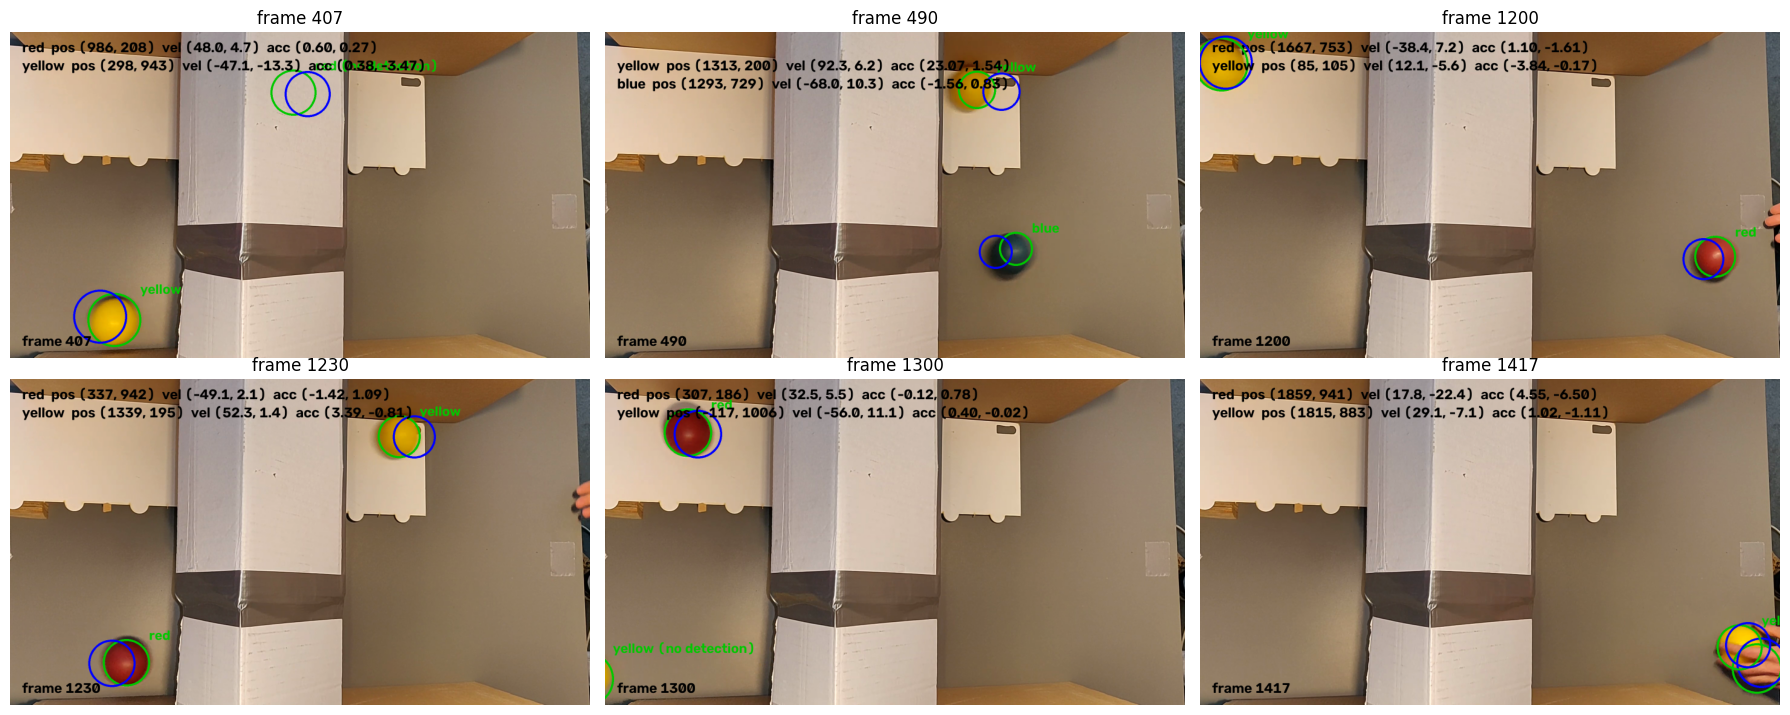

In [6]:
snapshots_ch, errors_ch = track_video('rolling_ball_challenge.mp4', 'tracked_balls_challenge.mp4', ['red', 'yellow', 'blue'],
                                      snapshot_frames=(407, 490, 1200, 1230, 1300, 1417))

print(f'Median prediction error over all detections: {np.median(errors_ch):.1f} px')
show_snapshots(snapshots_ch)

## Final comments

### First video

For the single ball video we used `HoughCircles` to find candidate circles. To remove false positives, each candidate is compared with the closest circle centre in the previous frame, and only candidates that moved more than a minimum and less than a maximum distance are accepted. This removes static circles in the background, and is the same movement based idea we used to track the robots in the week 2 weekly project. Since Hough does not match points between frames like optical flow does, we use the closest centre in the previous frame instead.

The accepted centre is the measurement Z in the Kalman update. When there is no measurement, the filter only predicts. The image shows the estimated current position and the predicted position for the next frame.

### Challenge

For the challenge we detect the balls by colour instead, with an HSV mask per colour (red, yellow and blue) and `HoughCircles` on that mask. Each colour gets its own Kalman filter with position, velocity and acceleration, and we added process noise Q to the prediction so the filter keeps following the measurements. A detection that is far from the prediction starts a new track instead of being fused into the old one, and a track is dropped when its ball leaves the image.

All three balls are tracked, and since each colour has its own filter they never get mixed up. When a ball goes behind the box, its filter keeps predicting and picks it up again on the other side (frame 407). The blue ball only passes once, around frame 490. The tight red colour range and the gating fixed most of the problems in this video, but the hand pushing the balls is still sometimes detected as the red ball (frame 1417). With identical balls we could not use colour, so we would have to match each detection to the closest prediction instead. The full result is saved in `tracked_balls_challenge.mp4`.


Note: We used generative AI to help with the code and comments.